# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Veterinary Health Dataset](https://www.kaggle.com/datasets/blaineee/veterinary-health-and-parasitology-dataset)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from tensorflow import keras
from tensorflow.keras import layers

/kaggle/input/datasets/blaineee/veterinary-health-and-parasitology-dataset/Veterinary_Clinic_Dataset.csv


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('Veterinary_Clinic_Dataset.csv')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake lofelineion,Body condition score,ear discharge type,ear canal status,ear microscopy,alopecia pattern,skin lesions,ectoparasite load,skin scrape result,wood lamp fungal,physical examination notes,additional clinical notes,definitive diagnosis
0,25021825,rescued,2/28/2025,NaN,canine,Aspin,4 years,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Purulent exudate,"Inflamed, exudative",rods/cocci,Multifocal trunk,"Papules, pustules, epidermal collarettes",0,Negative (Secondary pyoderma),Negative,ADR. Handler reports persistent scratching and...,Rescue case: Animal huddled inside a discarded...,Bacterial Dermatitis and Bacterial Otitis
1,23110410,owned,NaN,11/13/2023,canine,Shih Tzu,9 years,male,9.7,39.1,NaN,NaN,4.0,NaN,Normal,negative,"Generalized pruritic areas, face, paws, flanks","Erythema, excoriations, self-trauma wounds",0,Negative,Negative,BAR. Patient exhibits intense pruritus and sel...,Preventative: Frontline Plus. Outdoor-access p...,Atopic Dermatitis
2,23124507,owned,NaN,12/2/2023,canine,Golden Retriever,12 weeks,male,11.7,39.1,NaN,NaN,3.0,Purulent exudate,"Inflamed, exudative",rods/cocci,Multifocal trunk,"Papules, pustules, epidermal collarettes",0,Negative (Secondary pyoderma),Negative,BAR. Physical examination reveals active scrat...,Preventative: Bravecto. Outdoor active pet wal...,Bacterial Dermatitis and Bacterial Otitis
3,23014013,owned,NaN,2023-01-07,feline,Puspin,12 years,female,4.1,38.7,NaN,NaN,3.0,"Waxy, dark brown exudate","Erythematous, edematous",Malassezia,NaN,NaN,0,Negative,Negative,QAR. Clinical inspection shows marked skin rea...,Preventative: Advocate. Outdoor active pet wal...,Ear Mites and Yeast Otitis
4,24073658,rescued,7/17/2024,NaN,canine,Aspin,3 years,female,8.1,39.0,79.0,"Comembo, Makati City",3.0,"Dry, coffee-ground-like debris","Pruritic, inflamed",otodectes cynotis,NaN,NaN,2,Negative,Negative,QAR. Patient exhibits intense pruritus and sel...,Rescue case: Animal huddled inside a discarded...,Ear Mites


## last Five row

In [4]:
df.tail()

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake lofelineion,Body condition score,ear discharge type,ear canal status,ear microscopy,alopecia pattern,skin lesions,ectoparasite load,skin scrape result,wood lamp fungal,physical examination notes,additional clinical notes,definitive diagnosis
1995,25097643,owned,NaN,2025-09-02,canine,Aspin,9 months,female,13.3,39.0,104.0,NaN,7.0,NaN,Normal,negative,Multifocal trunk,"Papules, pustules, epidermal collarettes",0,Negative (Secondary pyoderma),Negative,"BAR, No C/S/V/D. Patient exhibits intense prur...",Preventative: Bravecto. Recently boarded at a ...,Bacterial Dermatitis
1996,23052008,rescued,5/20/2023,NaN,canine,French Bullcanine,7 years,female,22.0,38.9,NaN,Makati Central Business District,5.0,NaN,Normal,negative,"Generalized pruritic areas, face, paws, flanks","Erythema, excoriations, self-trauma wounds",1,Negative,Negative,AH. Patient exhibits intense pruritus and self...,Rescue case: Animal lodged tightly between con...,Atopic Dermatitis
1997,24124383,rescued,12/18/2024,NaN,canine,Aspin,11 weeks,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,NaN,Normal,negative,Circular patches on head/forelimbs,"Scaling, crusting annular lesions",0,Negative,Positive,ADR. Handler reports persistent scratching and...,Rescue case: Animal lodged tightly between con...,Ringworm
1998,24127367,rescued,12/19/2024,NaN,feline,Puspin,10 years,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Purulent exudate,"Inflamed, exudative",rods/cocci,Multifocal trunk,"Papules, pustules, epidermal collarettes",1,Negative (Secondary pyoderma),Negative,BAR. Handler reports persistent scratching and...,Rescue case: Animal shivering inside a drainag...,Bacterial Dermatitis and Bacterial Otitis
1999,24034062,rescued,3/15/2024,NaN,feline,Siamese,12 weeks,female,2.0,38.3,NaN,"Bel-Air, Makati City",7.0,"Waxy, dark brown exudate","Erythematous, edematous",Malassezia,NaN,NaN,1,Negative,Negative,AH. Handler reports persistent scratching and ...,Rescue case: Animal shivering inside a drainag...,Ear Mites and Yeast Otitis


## Shape of our dataset

In [5]:
df.shape

(2000, 24)

## List out all columns

In [6]:
df.columns

Index(['Patient ID', 'ownership_status', 'intake date', 'booking date',
       'species', 'breed', 'age', 'sex', 'weight', 'temperature', 'heart rate',
       'intake lofelineion', 'Body condition score', 'ear discharge type',
       'ear canal status', 'ear microscopy', 'alopecia pattern',
       'skin lesions', 'ectoparasite load', 'skin scrape result',
       'wood lamp fungal', 'physical examination notes',
       'additional clinical notes', 'definitive diagnosis'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

Patient ID                      int64
ownership_status               object
intake date                    object
booking date                   object
species                        object
breed                          object
age                            object
sex                            object
weight                        float64
temperature                   float64
heart rate                    float64
intake lofelineion             object
Body condition score          float64
ear discharge type             object
ear canal status               object
ear microscopy                 object
alopecia pattern               object
skin lesions                   object
ectoparasite load               int64
skin scrape result             object
wood lamp fungal               object
physical examination notes     object
additional clinical notes      object
definitive diagnosis           object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient ID                  2000 non-null   int64  
 1   ownership_status            2000 non-null   object 
 2   intake date                 866 non-null    object 
 3   booking date                1134 non-null   object 
 4   species                     2000 non-null   object 
 5   breed                       2000 non-null   object 
 6   age                         2000 non-null   object 
 7   sex                         2000 non-null   object 
 8   weight                      2000 non-null   float64
 9   temperature                 2000 non-null   float64
 10  heart rate                  1672 non-null   float64
 11  intake lofelineion          866 non-null    object 
 12  Body condition score        1940 non-null   float64
 13  ear discharge type          1326 

## Check Null Value

In [9]:
df.isnull().sum()

Patient ID                       0
ownership_status                 0
intake date                   1134
booking date                   866
species                          0
breed                            0
age                              0
sex                              0
weight                           0
temperature                      0
heart rate                     328
intake lofelineion            1134
Body condition score            60
ear discharge type             674
ear canal status                 0
ear microscopy                   0
alopecia pattern               676
skin lesions                   676
ectoparasite load                0
skin scrape result              33
wood lamp fungal                 0
physical examination notes       0
additional clinical notes        0
definitive diagnosis             0
dtype: int64

## Handle Null Feachers

In [10]:
df['intake date'] = pd.to_datetime(df['intake date'], errors='coerce')
df['booking date'] = pd.to_datetime(df['booking date'], errors='coerce')

df['intake date'] = df['intake date'].fillna(df['intake date'].mode()[0])
df['booking date'] = df['booking date'].fillna(df['booking date'].mode()[0])

df['heart rate'] = df['heart rate'].fillna(df['heart rate'].median())

df['intake lofelineion'] = df['intake lofelineion'].fillna('Unknown')

df['Body condition score'] = df['Body condition score'].fillna(df['Body condition score'].median())

df['ear discharge type'] = df['ear discharge type'].fillna('Not Recorded')

df['alopecia pattern'] = df['alopecia pattern'].fillna('Not Recorded')
df['skin lesions'] = df['skin lesions'].fillna('Not Recorded')

df['skin scrape result'] = df['skin scrape result'].fillna('Not Recorded')

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Patient ID                    0
ownership_status              0
intake date                   0
booking date                  0
species                       0
breed                         0
age                           0
sex                           0
weight                        0
temperature                   0
heart rate                    0
intake lofelineion            0
Body condition score          0
ear discharge type            0
ear canal status              0
ear microscopy                0
alopecia pattern              0
skin lesions                  0
ectoparasite load             0
skin scrape result            0
wood lamp fungal              0
physical examination notes    0
additional clinical notes     0
definitive diagnosis          0
dtype: int64


## Check Dupicate Value

In [11]:
df.duplicated().sum()

np.int64(0)

## Summary

In [12]:
df.describe()

,Patient ID,intake date,booking date,weight,temperature,heart rate,Body condition score,ectoparasite load
count,2.000000e+03,2000,2000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000
mean,2.404418e+07,2023-07-10 14:03:07.200000,2023-08-29 18:12:14.400000,7.652150,38.714600,129.53950,4.973500,0.388500
min,2.301009e+07,2023-01-10 00:00:00,2023-01-10 00:00:00,0.700000,38.000000,66.00000,3.000000,0.000000
25%,2.309690e+07,2023-01-17 00:00:00,2023-01-15 00:00:00,3.100000,38.500000,103.00000,4.000000,0.000000
50%,2.406290e+07,2023-01-17 00:00:00,2023-01-15 00:00:00,4.500000,38.700000,118.00000,5.000000,0.000000
75%,2.503390e+07,2023-09-14 12:00:00,2024-03-19 06:00:00,9.700000,39.000000,160.00000,6.000000,1.000000
max,2.512987e+07,2025-12-28 00:00:00,2025-12-27 00:00:00,35.800000,39.300000,230.00000,7.000000,3.000000
std,8.212429e+05,NaN,NaN,7.340566,0.295957,38.98912,1.402776,0.679558


# EDA

In [13]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

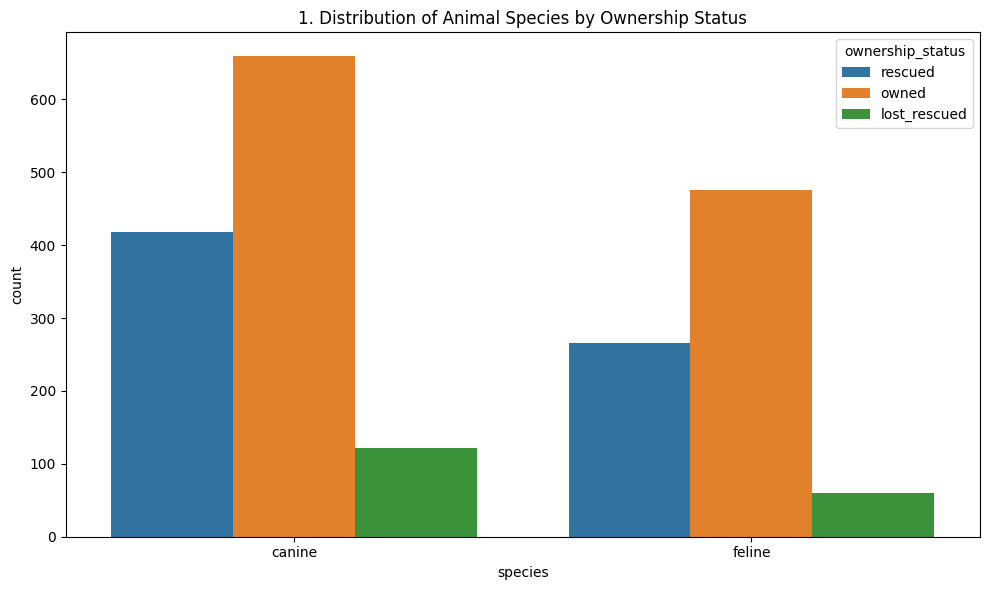

In [14]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='species', hue='ownership_status')
plt.title(f'{plot_no}. Distribution of Animal Species by Ownership Status')
show_fig()
plot_no += 1

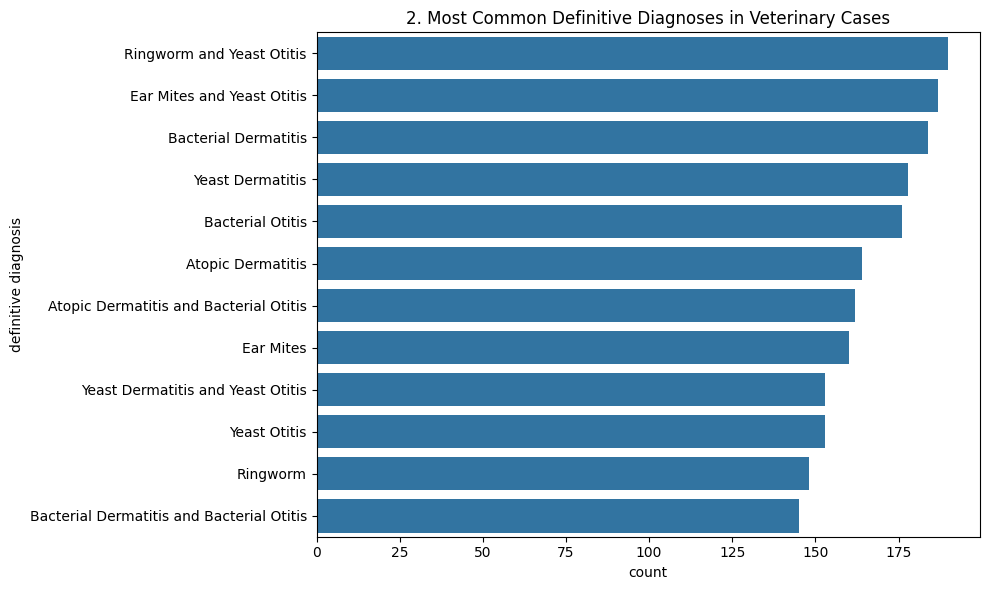

In [15]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, y='definitive diagnosis', order=df['definitive diagnosis'].value_counts().index)
plt.title(f'{plot_no}. Most Common Definitive Diagnoses in Veterinary Cases')
show_fig()
plot_no += 1

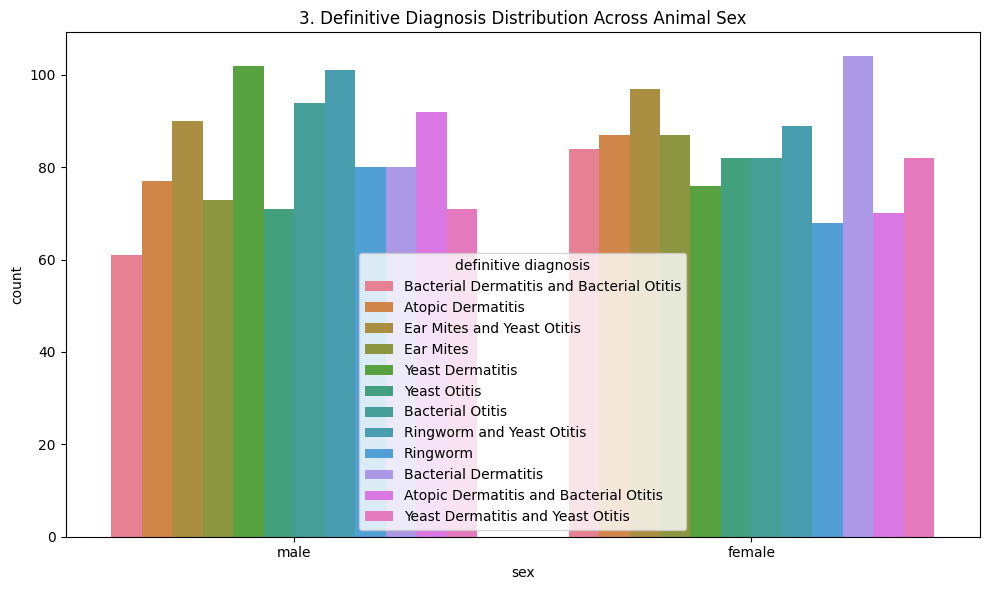

In [16]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='sex', hue='definitive diagnosis')
plt.title(f'{plot_no}. Definitive Diagnosis Distribution Across Animal Sex')
show_fig()
plot_no += 1

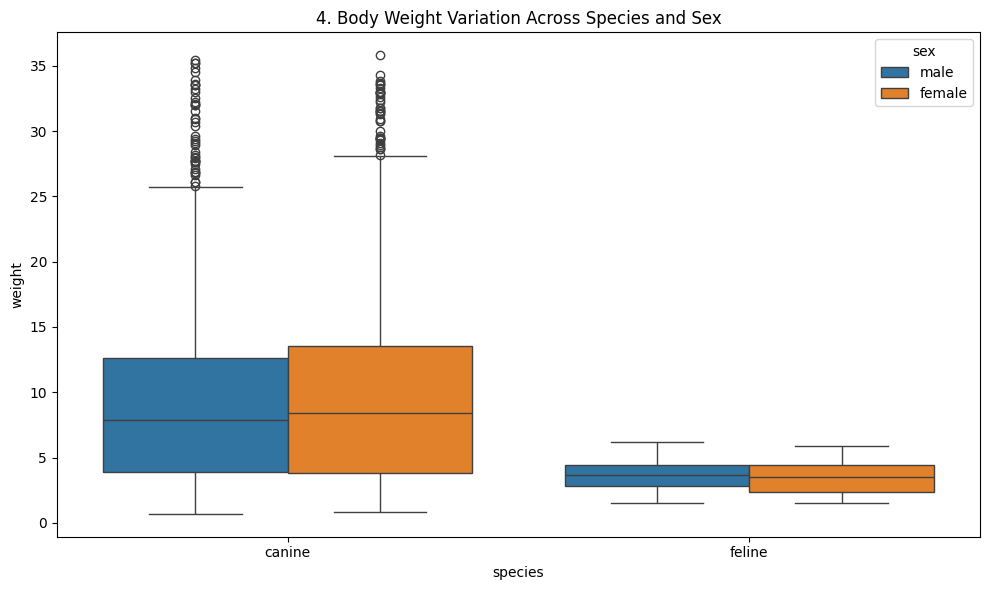

In [17]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='species', y='weight', hue='sex')
plt.title(f'{plot_no}. Body Weight Variation Across Species and Sex')
show_fig()
plot_no += 1

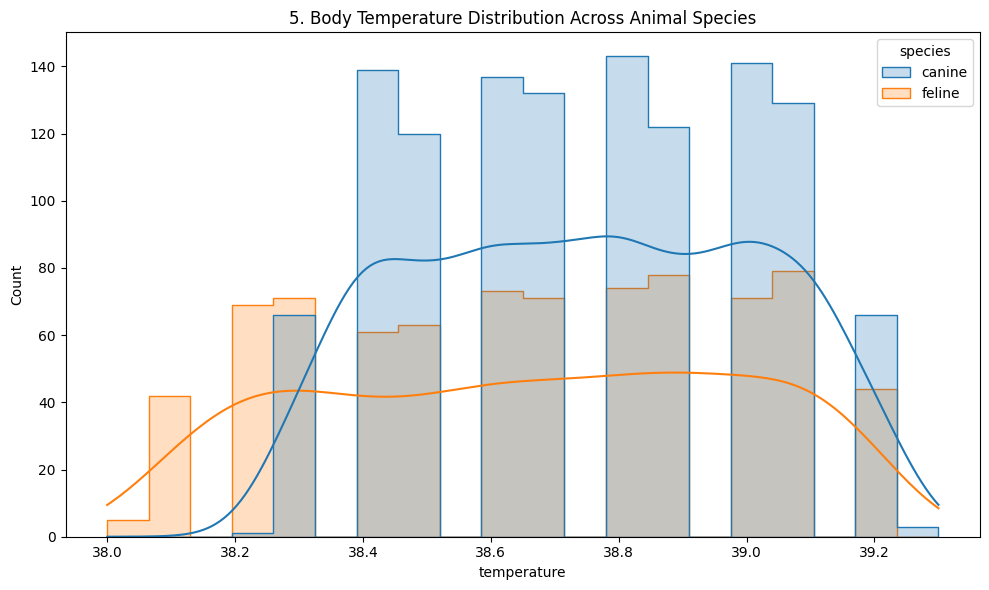

In [18]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='temperature', hue='species', kde=True, bins=20, element='step')
plt.title(f'{plot_no}. Body Temperature Distribution Across Animal Species')
show_fig()
plot_no += 1

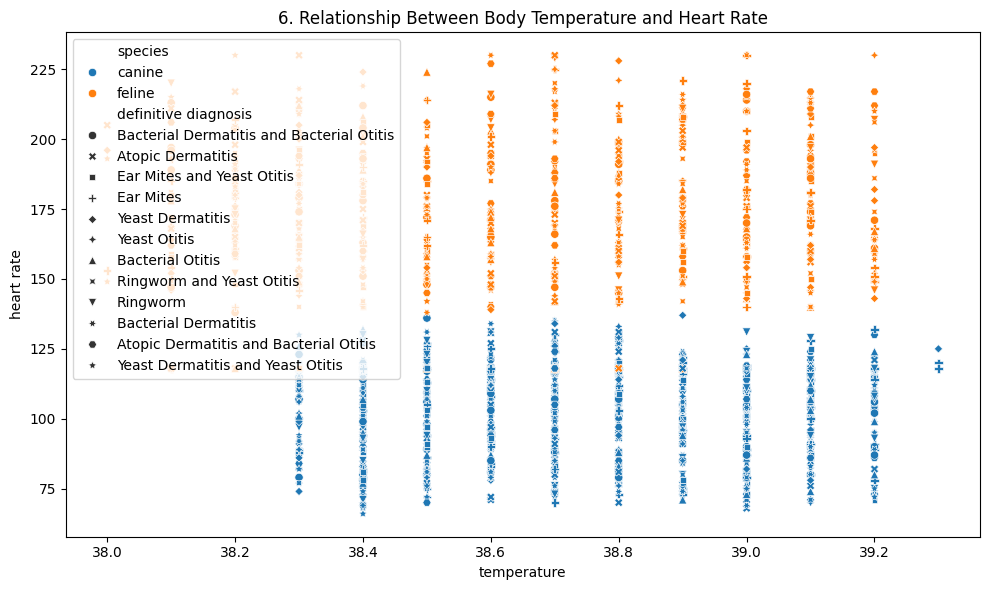

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='temperature', y='heart rate', hue='species', style='definitive diagnosis')
plt.title(f'{plot_no}. Relationship Between Body Temperature and Heart Rate')
show_fig()
plot_no += 1

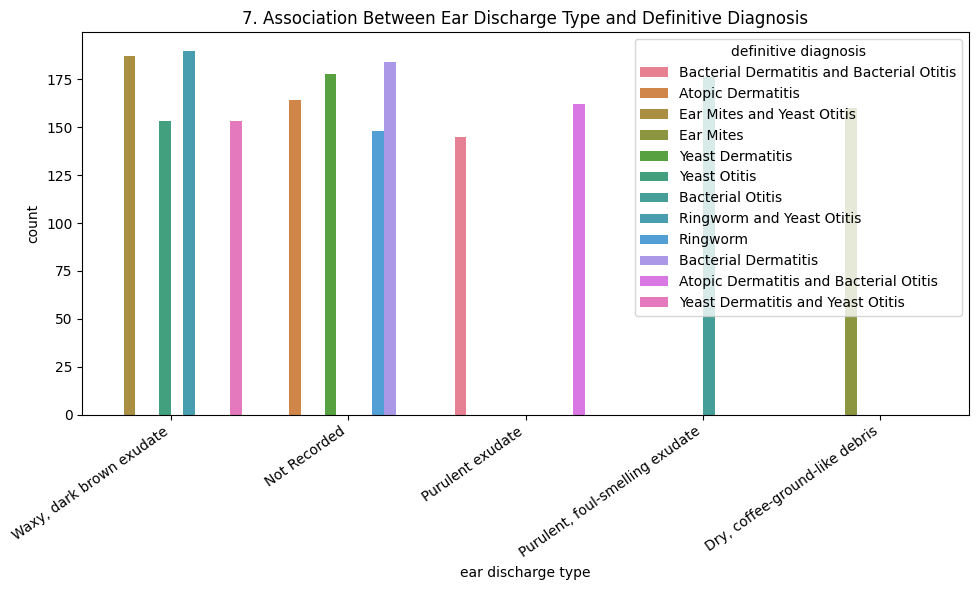

In [20]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='ear discharge type', hue='definitive diagnosis', order=df['ear discharge type'].value_counts().index)
plt.title(f'{plot_no}. Association Between Ear Discharge Type and Definitive Diagnosis')
plt.xticks(rotation=35, ha='right')
show_fig()
plot_no += 1

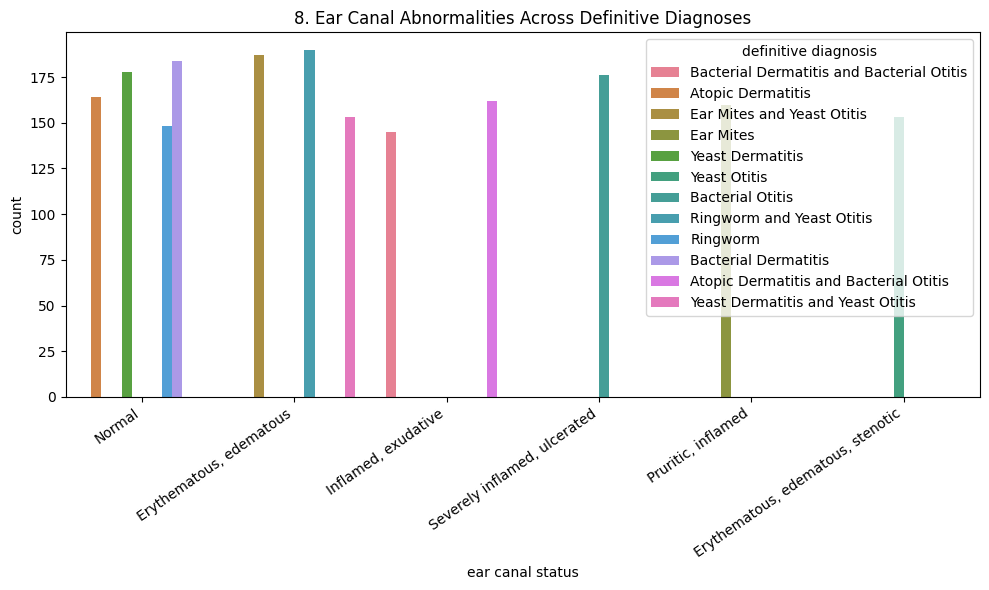

In [21]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='ear canal status', hue='definitive diagnosis', order=df['ear canal status'].value_counts().index)
plt.title(f'{plot_no}. Ear Canal Abnormalities Across Definitive Diagnoses')
plt.xticks(rotation=35, ha='right')
show_fig()
plot_no += 1

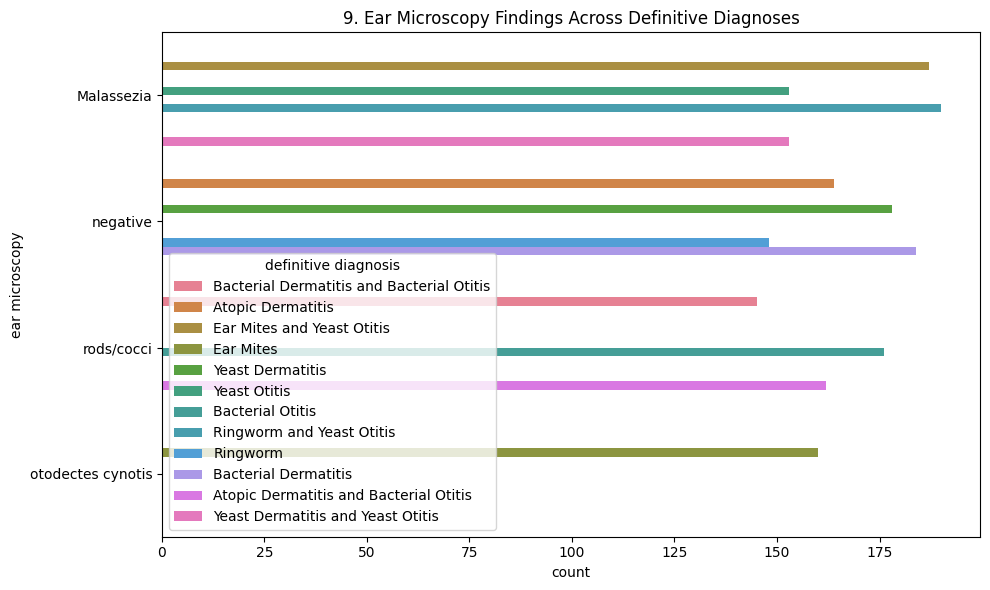

In [22]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, y='ear microscopy', hue='definitive diagnosis', order=df['ear microscopy'].value_counts().index)
plt.title(f'{plot_no}. Ear Microscopy Findings Across Definitive Diagnoses')
show_fig()
plot_no += 1

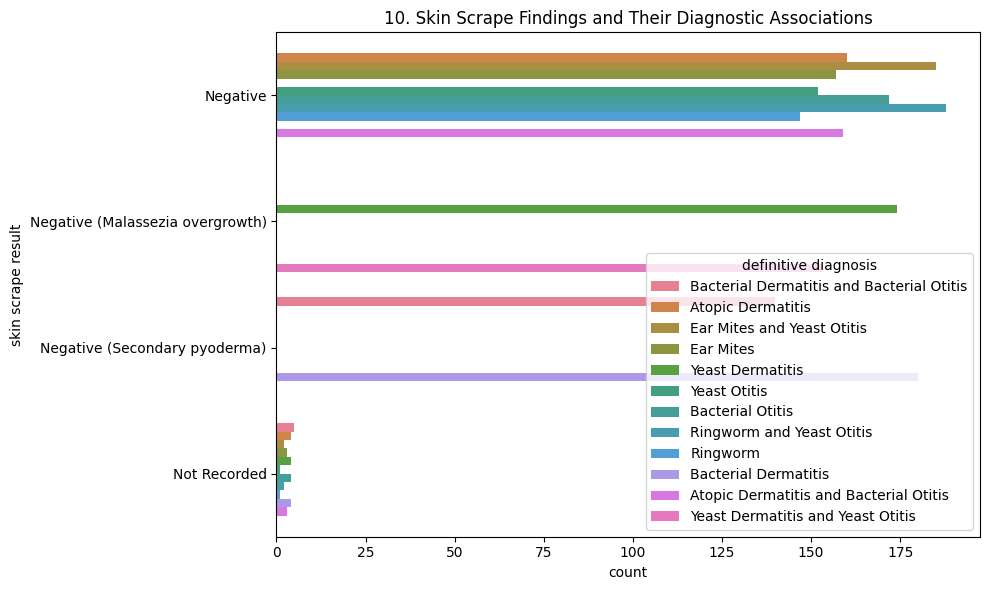

In [23]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, y='skin scrape result', hue='definitive diagnosis', order=df['skin scrape result'].value_counts().index)
plt.title(f'{plot_no}. Skin Scrape Findings and Their Diagnostic Associations')
show_fig()
plot_no += 1

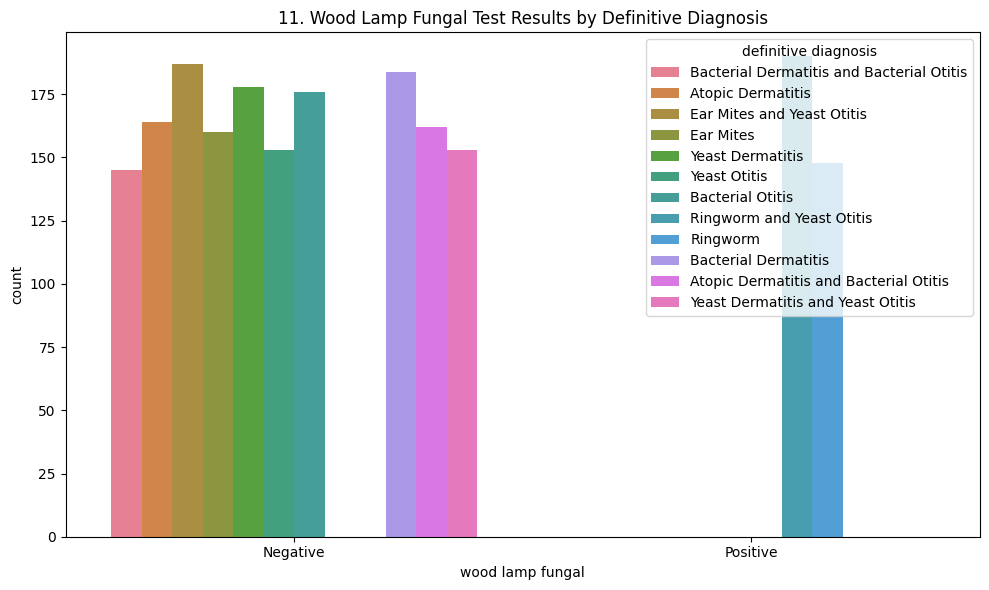

In [24]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='wood lamp fungal', hue='definitive diagnosis')
plt.title(f'{plot_no}. Wood Lamp Fungal Test Results by Definitive Diagnosis')
show_fig()
plot_no += 1

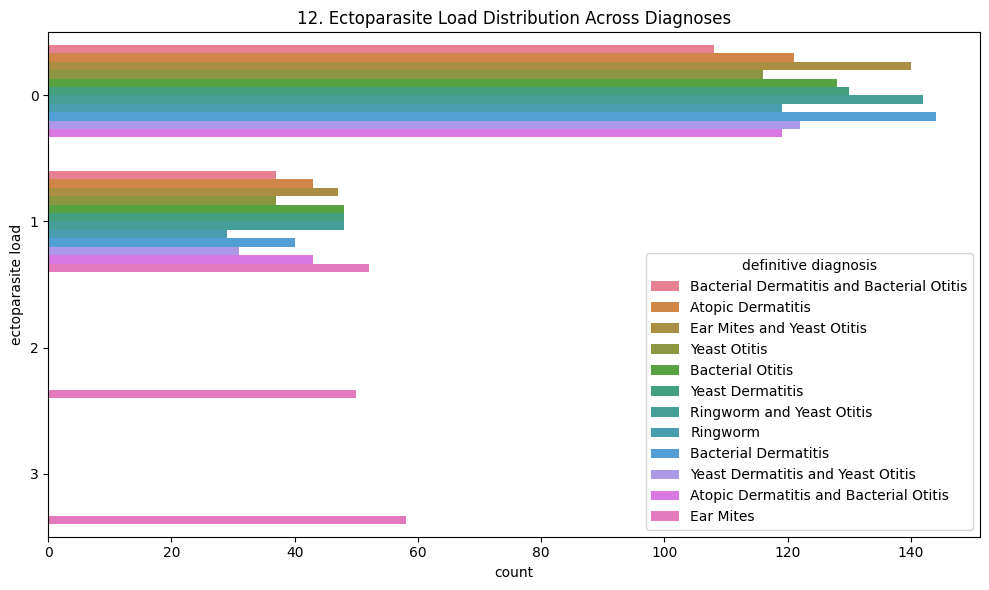

In [25]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, y='ectoparasite load', hue='definitive diagnosis')
plt.title(f'{plot_no}. Ectoparasite Load Distribution Across Diagnoses')
show_fig()
plot_no += 1

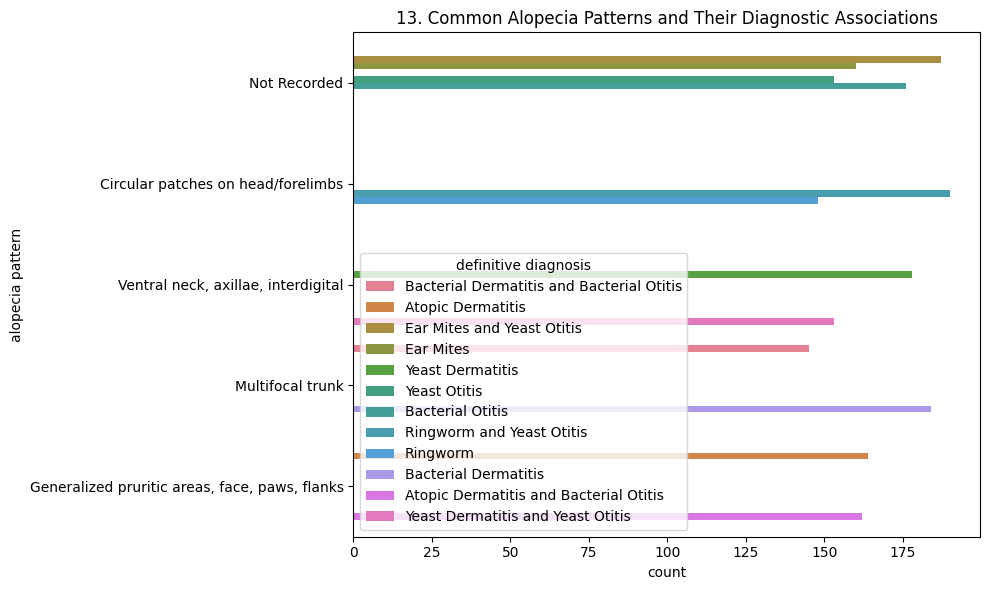

In [26]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, y='alopecia pattern', hue='definitive diagnosis', order=df['alopecia pattern'].value_counts().head(10).index)
plt.title(f'{plot_no}. Common Alopecia Patterns and Their Diagnostic Associations')
show_fig()
plot_no += 1

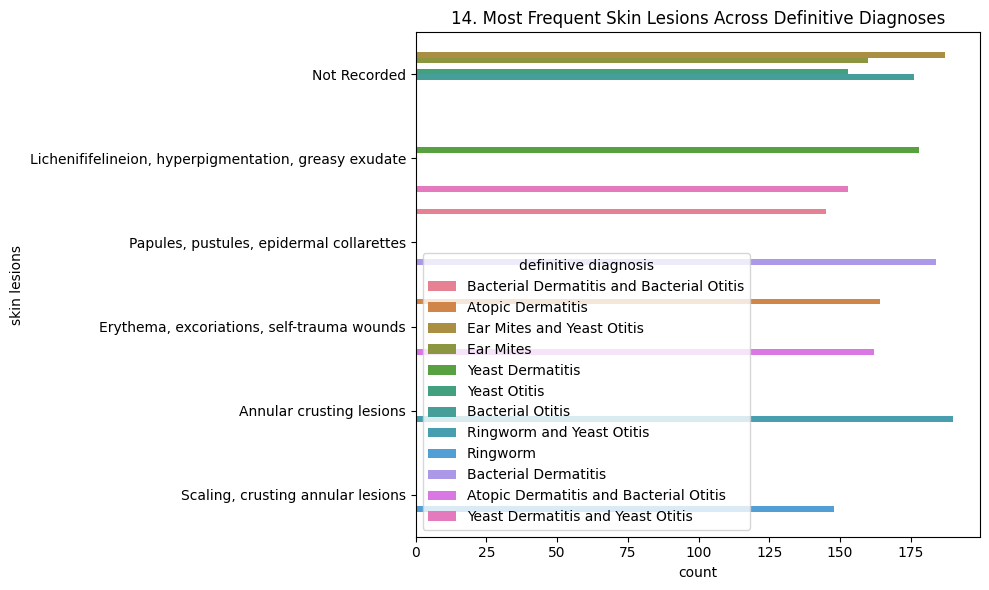

In [27]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, y='skin lesions', hue='definitive diagnosis', order=df['skin lesions'].value_counts().head(10).index)
plt.title(f'{plot_no}. Most Frequent Skin Lesions Across Definitive Diagnoses')
show_fig()
plot_no += 1

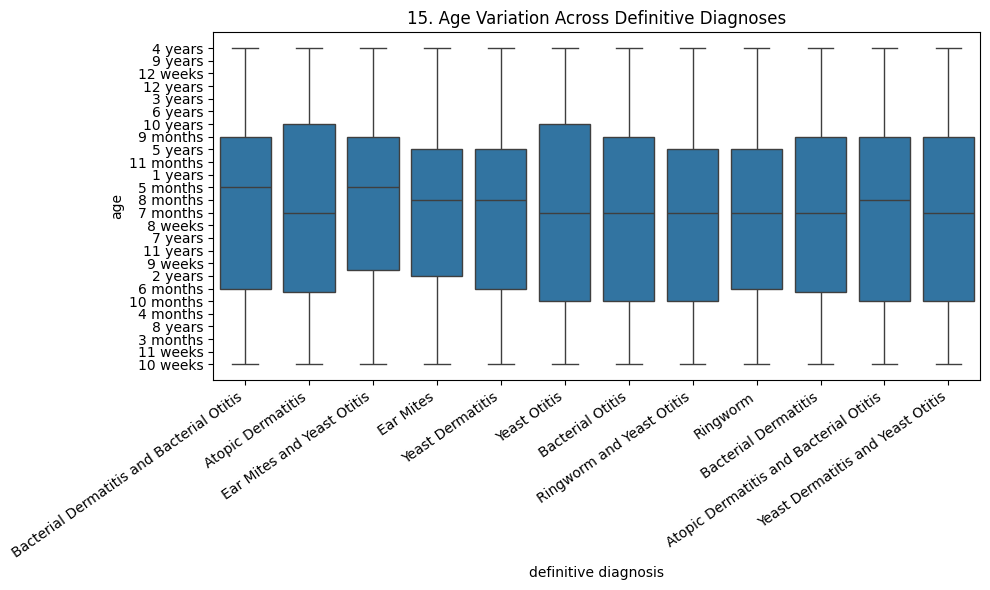

In [28]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='definitive diagnosis', y='age')
plt.title(f'{plot_no}. Age Variation Across Definitive Diagnoses')
plt.xticks(rotation=35, ha='right')
show_fig()
plot_no += 1

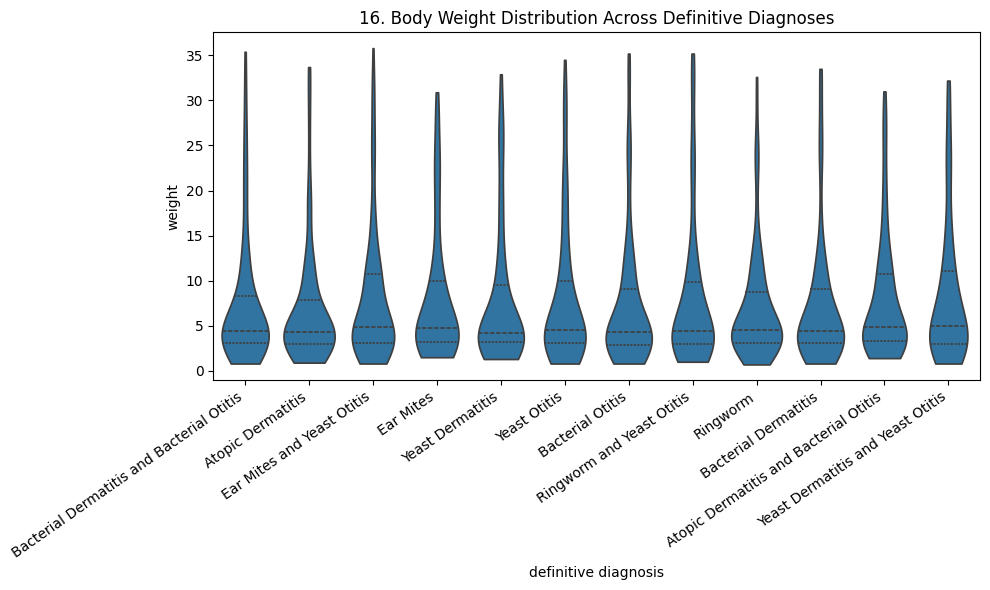

In [29]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='definitive diagnosis', y='weight', inner='quartile', cut=0)
plt.title(f'{plot_no}. Body Weight Distribution Across Definitive Diagnoses')
plt.xticks(rotation=35, ha='right')
show_fig()
plot_no += 1

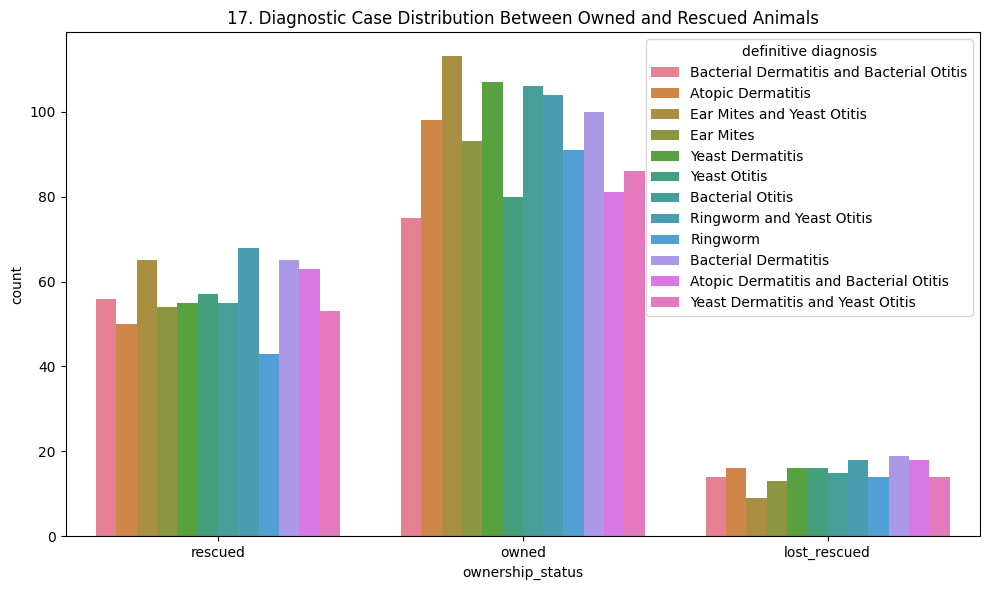

In [30]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='ownership_status', hue='definitive diagnosis')
plt.title(f'{plot_no}. Diagnostic Case Distribution Between Owned and Rescued Animals')
show_fig()
plot_no += 1

<Figure size 1000x600 with 0 Axes>

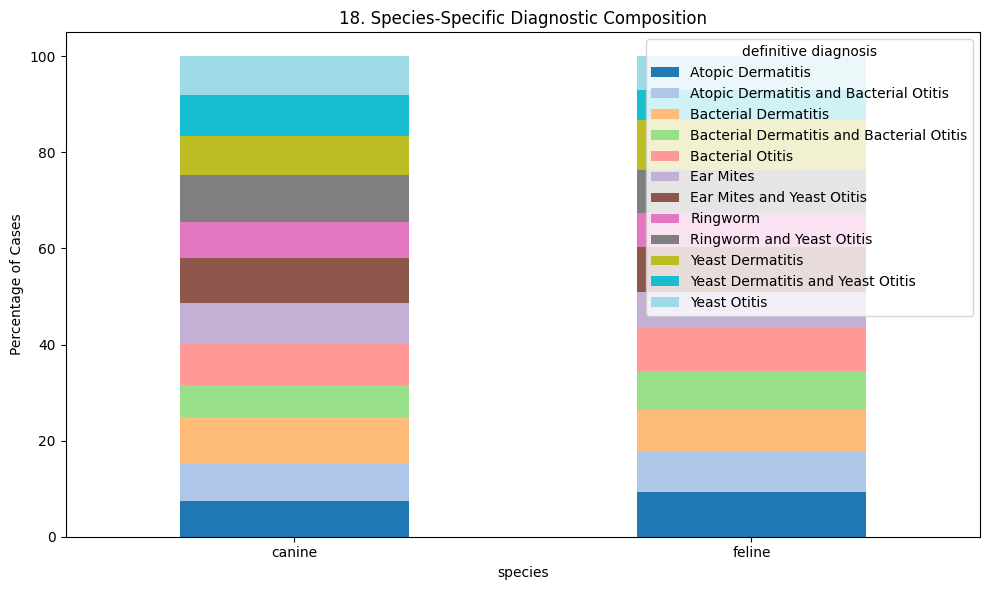

In [31]:
fig = plt.figure(figsize=(10,6))
diagnosis_by_species = pd.crosstab(df['species'], df['definitive diagnosis'], normalize='index') * 100
diagnosis_by_species.plot(kind='bar', stacked=True, figsize=(10,6), colormap='tab20')
plt.ylabel('Percentage of Cases')
plt.title(f'{plot_no}. Species-Specific Diagnostic Composition')
plt.xticks(rotation=0)
show_fig()
plot_no += 1

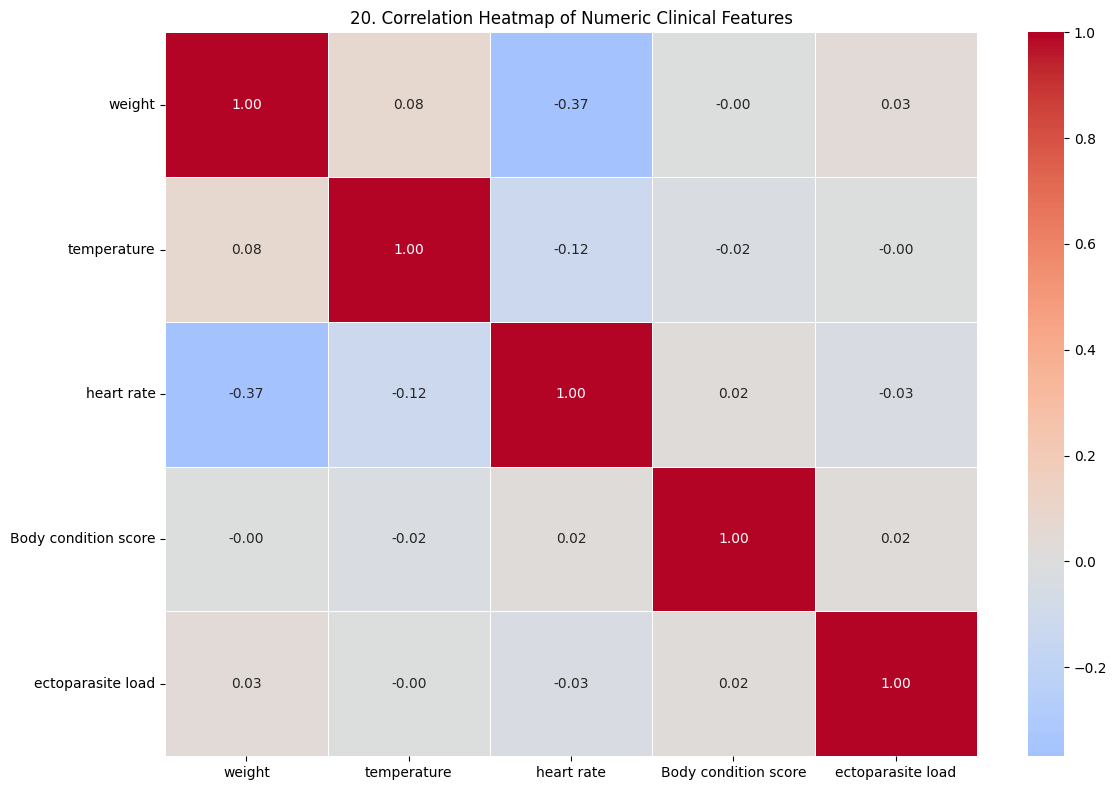

In [33]:
fig = plt.figure(figsize=(12,8))
numeric_df = df.select_dtypes(include='number').drop(columns=['Patient ID'], errors='ignore')
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', center=0, linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Numeric Clinical Features')
show_fig()
plot_no += 1

# Model Training

## Machine Learning

### Prepare the dataset

In [34]:
data = df.drop(columns=['Patient ID'], errors='ignore').copy()
data.columns = data.columns.str.strip()
data = data.loc[:, ~data.columns.duplicated()]
data = data.replace(r'^\s*$', np.nan, regex=True)

### Prepare the target variable

In [35]:
target = 'weight'
data[target] = pd.to_numeric(data[target], errors='coerce')
data = data.dropna(subset=[target])

### Remove target leakage and irrelevant columns

In [36]:
X = data.drop(columns=[target, 'definitive diagnosis'], errors='ignore')
y = data[target]

### Remove columns with entirely missing values

In [37]:
X = X.dropna(axis=1, how='all')

### Identify feature types

In [38]:
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

### Clean feature values

In [39]:
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors='coerce')

for col in categorical_cols:
    X[col] = X[col].astype('object')

### Impute missing numeric and categorical values

In [40]:
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        max_categories=30,
        sparse_output=False
    ))
])

### Combine preprocessing steps

In [41]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_cols),
    ('cat', categorical_pipe, categorical_cols)
])

### Build the regression model

In [42]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    ))
])

### Split the dataset

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### Train the model

In [44]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['temperature', 'heart rate',
                                                   'Body condition score',
                                                   'ectoparasite load']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 max_categories=30,
                                                                                 spars...
                                                   'breed', 'age', 'sex',
                                                   'intake lofelineion',
                                                   'ear discharge type',
                                                   'ear canal status',
                                                   'ear microscopy',
                                                   'alopecia pattern',
                                                   'skin lesions',
                                                   'skin scrape result',
                                                   'wood lamp fungal',
                                                   'physical examination notes',
                                                   'additional clinical '
                                                   'notes'])])),
                ('regressor',
                 HistGradientBoostingRegressor(l2_regularization=1.0,
                                               learning_rate=0.08, max_iter=200,
                                               max_leaf_nodes=20,
                                               random_state=42))])

### Generate predictions

In [45]:
y_pred = model.predict(X_test)

### Evaluate model performance

In [46]:
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

R² Score: 0.6478
MAE: 2.4179
RMSE: 4.0133


### Plot actual versus predicted values

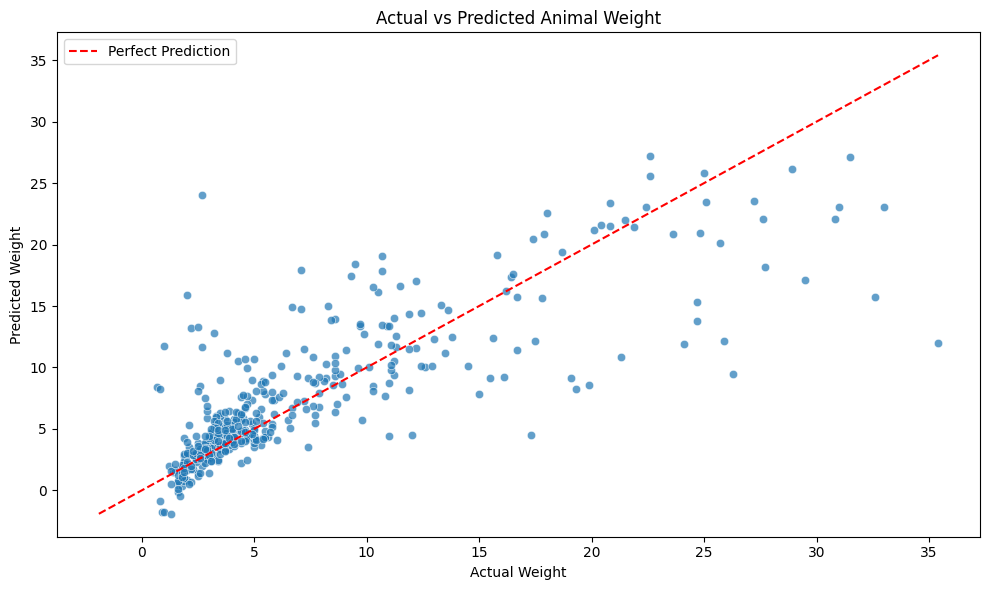

In [47]:
fig = plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], 'r--', label='Perfect Prediction')
plt.xlabel('Actual Weight')
plt.ylabel('Predicted Weight')
plt.title('Actual vs Predicted Animal Weight')
plt.legend()
show_fig()

## Deep Learning

### Prepare the dataset


In [ ]:
data = df.drop(columns=['Patient ID'], errors='ignore').copy()
data.columns = data.columns.str.strip()
data = data.loc[:, ~data.columns.duplicated()]
data = data.replace(r'^\s*$', np.nan, regex=True)

### Prepare the target

In [ ]:
target = 'weight'
data[target] = pd.to_numeric(data[target], errors='coerce')
data = data.dropna(subset=[target])

### Separate features and target

In [ ]:
X = data.drop(columns=[target, 'definitive diagnosis'], errors='ignore')
y = data[target]

### Remove empty columns

In [ ]:
X = X.dropna(axis=1, how='all')

### Identify feature types

In [ ]:
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

### Convert feature values

In [ ]:
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors='coerce')

for col in categorical_cols:
    X[col] = X[col].astype('object')

### Split the data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### Preprocess numeric and categorical features

In [ ]:
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        max_categories=30,
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_cols),
    ('cat', categorical_pipe, categorical_cols)
])

### Transform the features

In [ ]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

### Scale the target

In [ ]:
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
).astype(np.float32)

### Build the neural network

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.25),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.15),
    layers.Dense(64, activation='relu'),
    layers.Dense(1)
])

### Compile the model

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

### Stop training when validation performance stops improving

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

### Train the neural network

In [ ]:
history = model.fit(
    X_train,
    y_train_scaled,
    validation_split=0.2,
    epochs=150,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

### Predict actual weight values

In [ ]:
y_pred_scaled = model.predict(X_test, verbose=0)
y_pred = y_scaler.inverse_transform(y_pred_scaled).ravel()

### Evaluate model performance

In [ ]:
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

### Plot actual versus predicted values

In [ ]:
fig = plt.figure(figsize=(10, 6))
sns.scatterplot(x=np.asarray(y_test), y=y_pred, alpha=0.7)

low = min(np.min(y_test), np.min(y_pred))
high = max(np.max(y_test), np.max(y_pred))

plt.plot([low, high], [low, high], 'r--', label='Perfect Prediction')
plt.xlabel('Actual Weight')
plt.ylabel('Predicted Weight')
plt.title('Deep Learning: Actual vs Predicted Animal Weight')
plt.legend()
show_fig()

### Plot training and validation loss

2026-10-16 15:20:27.612113: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 1.4373 - mae: 0.9264 - val_loss: 1.1372 - val_mae: 0.7163
Epoch 2/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8460 - mae: 0.7024 - val_loss: 1.0766 - val_mae: 0.6997
Epoch 3/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6734 - mae: 0.6119 - val_loss: 0.9799 - val_mae: 0.6768
Epoch 4/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5906 - mae: 0.5873 - val_loss: 0.9885 - val_mae: 0.6520
Epoch 5/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5018 - mae: 0.5281 - val_loss: 0.9199 - val_mae: 0.6151
Epoch 6/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4374 - mae: 0.5058 - val_loss: 0.8927 - val_mae: 0.5752
Epoch 7/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3766 - mae: 0.4598 - val_loss: 0.8597 - val_mae: 0.5594
Epoch 8/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3524 - mae: 0.4468 - val_loss: 0.7978 - val_mae: 0.5411
Epoch 9/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.36

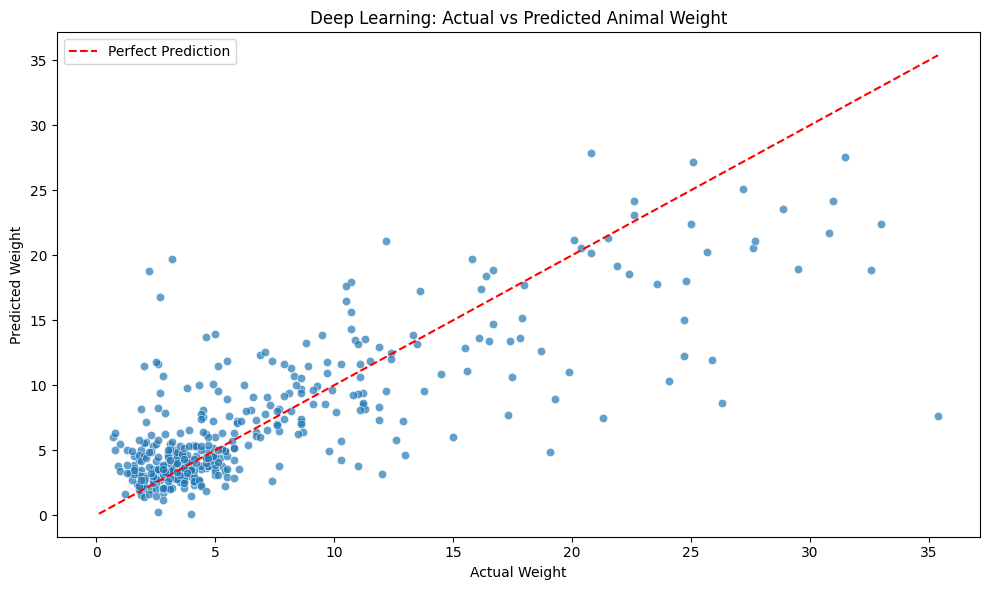

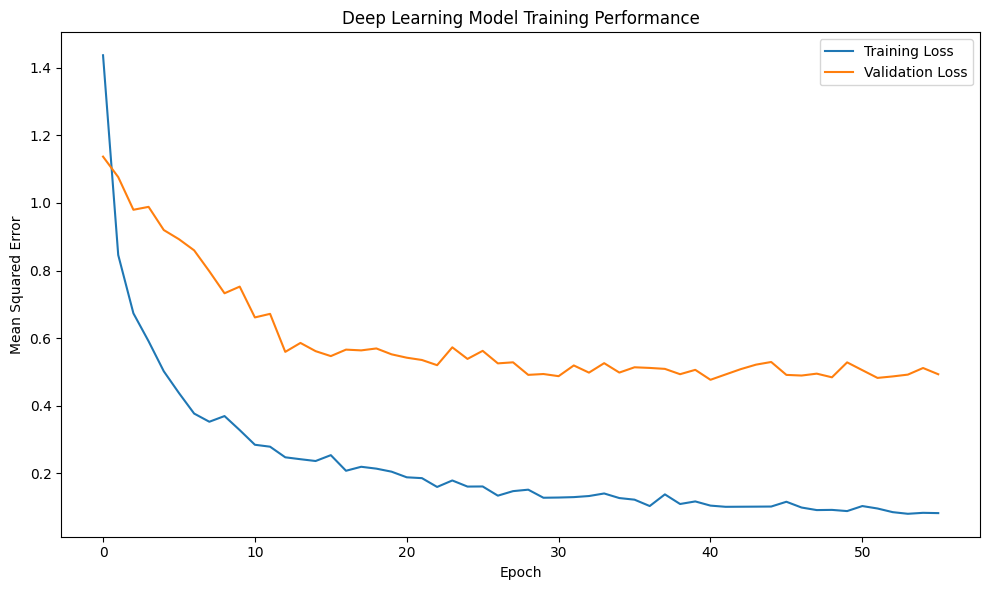

In [48]:
fig = plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('Deep Learning Model Training Performance')
plt.legend()
show_fig()

In [ ]:
model.summary()